In [1]:
%matplotlib widget
import numpy as np
import matplotlib, matplotlib.pyplot as plt

## Data Loading

In [2]:
from scipy.io import loadmat

In [3]:
Dataset = loadmat("sensor_data.mat")
print(Dataset.keys())

dict_keys(['__header__', '__version__', '__globals__', 'time_grid', 'high_end_imu', 'low_end_imu', 'odometer', 'reference_ins'])


In [4]:
time_grid = Dataset['time_grid'].flatten()
print(time_grid.shape)

(2496,)


In [5]:
# print(Dataset['high_end_imu'].dtype.names)
# novatel_acc_data = Dataset['high_end_imu']['accelerometer'][0,0]
# print(novatel_acc_data.shape)
# novatel_gyro_data = Dataset['high_end_imu']['gyroscope'][0,0].flatten()
# print(novatel_gyro_data.shape)

In [6]:
print(Dataset['low_end_imu'].dtype.names)
novatel_acc_data = Dataset['low_end_imu']['accelerometer'][0,0]
print(novatel_acc_data.shape)
novatel_gyro_data = Dataset['low_end_imu']['gyroscope'][0,0].flatten()
print(novatel_gyro_data.shape)

('accelerometer', 'gyroscope')
(2496, 3)
(2496,)


In [7]:
odom_speed = Dataset['odometer']['speed'][0,0].flatten()
print(odom_speed.shape)

(2496,)


In [8]:
print(Dataset['reference_ins'].dtype.names)

# Position

ref_altitude = Dataset['reference_ins']['altitude'][0,0].flatten()
ref_latitude = Dataset['reference_ins']['latitude'][0,0].flatten()
ref_longitude = Dataset['reference_ins']['longitude'][0,0].flatten()

print(ref_altitude.shape, ref_latitude.shape, ref_longitude.shape)

# Velocity

ref_ve = Dataset['reference_ins']['velocity_east'][0,0].flatten()
ref_vn = Dataset['reference_ins']['velocity_north'][0,0].flatten()
ref_vu = Dataset['reference_ins']['velocity_up'][0,0].flatten()

print(ref_ve.shape, ref_vn.shape, ref_vu.shape)

# Attitude

ref_az = Dataset['reference_ins']['azimuth'][0,0].flatten()
ref_pitch = Dataset['reference_ins']['pitch'][0,0].flatten()
ref_roll = Dataset['reference_ins']['roll'][0,0].flatten()

print(ref_az.shape, ref_pitch.shape, ref_roll.shape)

('altitude', 'latitude', 'longitude', 'velocity_east', 'velocity_north', 'velocity_up', 'azimuth', 'pitch', 'roll')
(2496,) (2496,) (2496,)
(2496,) (2496,) (2496,)
(2496,) (2496,) (2496,)


## Mechanization Loop

In [9]:
num_epochs = len(time_grid.flatten())
num_epochs

2496

In [10]:
# Defining some constants
a = 6378137 # Semi-major axis (meters)
ecc = 0.08181919 # Eccentricity
omega_e = 7.292115e-5 # Earth’s rotation rate (rad/s)

In [11]:
# Pre-allocating arrays for data logging

# Position
alt_est = np.zeros(num_epochs)
lat_est = np.zeros(num_epochs)
long_est = np.zeros(num_epochs)

# velcoity
ve_est = np.zeros(num_epochs)
vn_est = np.zeros(num_epochs)
vu_est = np.zeros(num_epochs)

# Attitude
yaw_est = np.zeros(num_epochs)
pitch_est = np.zeros(num_epochs)
roll_est = np.zeros(num_epochs)

In [12]:
# Logging initial values

# Position
alt_est[0] = ref_altitude[0]
lat_est[0] = np.radians(ref_latitude[0])
long_est[0] = np.radians(ref_longitude[0])

# Velocity
ve_est[0] = ref_ve[0]
vn_est[0] = ref_vn[0]
vu_est[0] = ref_vu[0]

# Attitude
yaw_est[0] = np.radians(-1 * ref_az[0])
pitch_est[0] = np.radians(ref_pitch[0])
roll_est[0] = np.radians(ref_roll[0])

In [13]:
for e in range(1, num_epochs):

    # extract sensor data

    # Novatel IMU data
    fx = novatel_acc_data[e, 0] - 0.041
    fy = 1 * novatel_acc_data[e, 1] - 0.552
    fz = novatel_acc_data[e, 2]
    omega_z = novatel_gyro_data[e] + 0.0016
    # odometer data
    v_od = odom_speed[e]
    
    if (v_od == 0):
        alt_est[e] = alt_est[e-1]
        lat_est[e] = lat_est[e-1]
        long_est[e] = long_est[e-1]
        yaw_est[e] = yaw_est[e-1]
        pitch_est[e] = pitch_est[e-1]
        roll_est[e] = roll_est[e-1]
        ve_est[e] = 0
        vn_est[e] = 0
        vu_est[e] = 0
        continue
    
    # calculate pitch and roll
    
    a_od = odom_speed[e] - odom_speed[e-1] # calculated acceleration from odometer speed data
    roll_est[e] = np.arctan2(- (fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(- (fy - a_od), np.sqrt(fx**2 + fz**2))

    # calculate Yaw angle
    R_n = a / np.sqrt(1 - (ecc**2) * (np.sin(lat_est[e-1])**2))
    yaw_est[e] = yaw_est[e-1] + ( (np.cos(pitch_est[e-1]) * np.cos(roll_est[e-1]) * omega_z) - (omega_e * np.sin(lat_est[e-1])) - (ve_est[e-1] * np.tan(lat_est[e-1]) / (R_n + alt_est[e-1])) )
    yaw_est[e] = yaw_est[e] % (2 * np.pi) # Normalize yaw to [0, 2π]

    # calculate velocity components
    ve_est[e] = -np.sin(yaw_est[e]) * np.cos(pitch_est[e]) * v_od
    vn_est[e] = np.cos(yaw_est[e]) * np.cos(pitch_est[e]) * v_od
    vu_est[e] = np.sin(pitch_est[e]) * v_od

    # calculate position components
    R_m = (a * (1 - ecc**2)) / ((1 - (ecc**2) * (np.sin(lat_est[e-1])**2)) ** (3/2))

    alt_est[e] = alt_est[e-1] + vu_est[e]
    
    lat_est[e] = lat_est[e-1] + (vn_est[e]) / (R_m + alt_est[e])
    lat_est[e] = (lat_est[e] + np.pi/2) % np.pi - np.pi/2 # Normalize latitude to [-π/2, π/2]

    long_est[e] = long_est[e-1] + (ve_est[e]) / ((R_n + alt_est[e]) * np.cos(lat_est[e]))
    long_est[e] = (long_est[e] + np.pi) % (2 * np.pi) - np.pi # Normalize longitude to [-π, π]


## Plotting

### Position

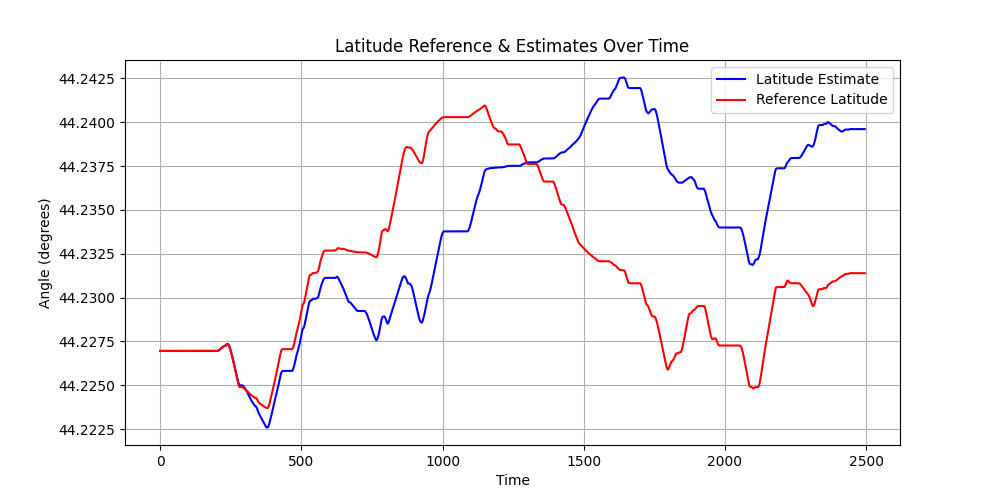

In [14]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, np.degrees(lat_est), label="Latitude Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_latitude, label="Reference Latitude", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Latitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

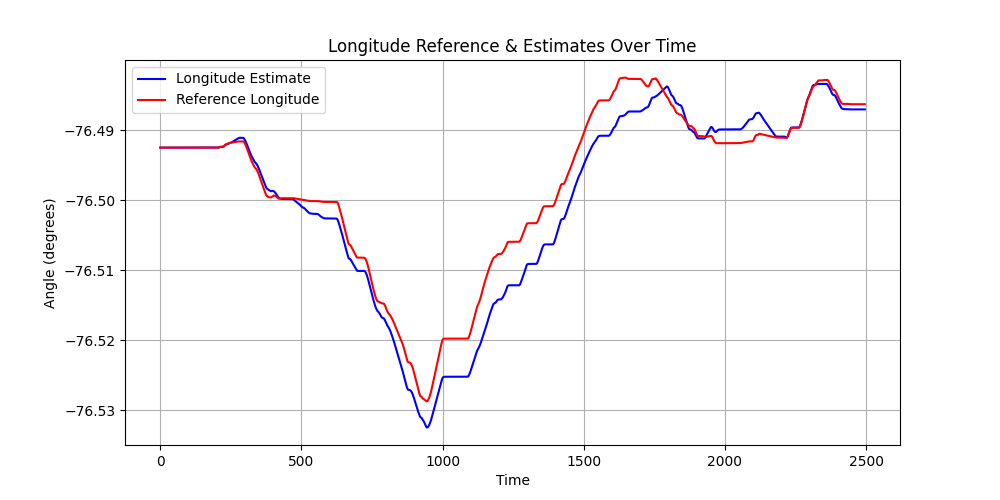

In [15]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, np.degrees(long_est), label="Longitude Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_longitude, label="Reference Longitude", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (degrees)")
plt.title("Longitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

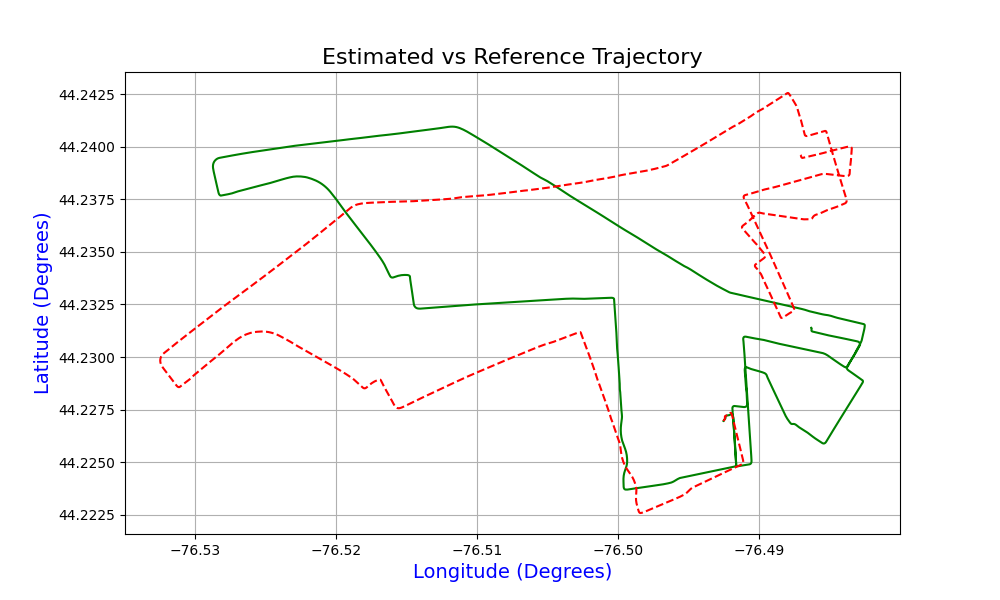

In [16]:
plt.figure(figsize=(10, 6))

# Plot reference trajectory in green
plt.plot(ref_longitude, ref_latitude, 'g-', label="Reference")

# Plot estimated trajectory in red (dashed line)
plt.plot(np.degrees(long_est), np.degrees(lat_est), 'r--', label="Un-Aided 3D RISS Mechanization")

# Labels and title
plt.xlabel("Longitude (Degrees)", fontsize=14, color='blue')
plt.ylabel("Latitude (Degrees)", fontsize=14, color='blue')
plt.title("Estimated vs Reference Trajectory", fontsize=16)

# Add a legend
#plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

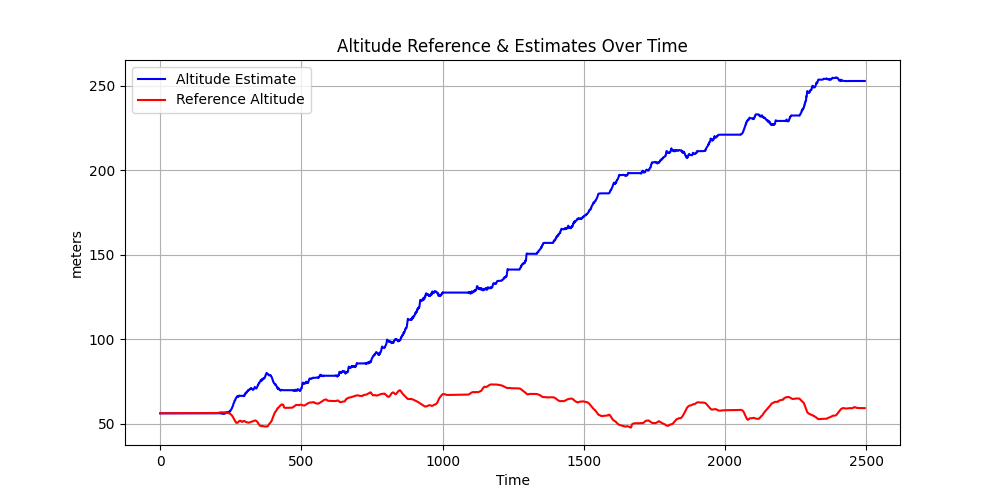

In [17]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, alt_est, label="Altitude Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_altitude, label="Reference Altitude", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("meters")
plt.title("Altitude Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

### Velocity

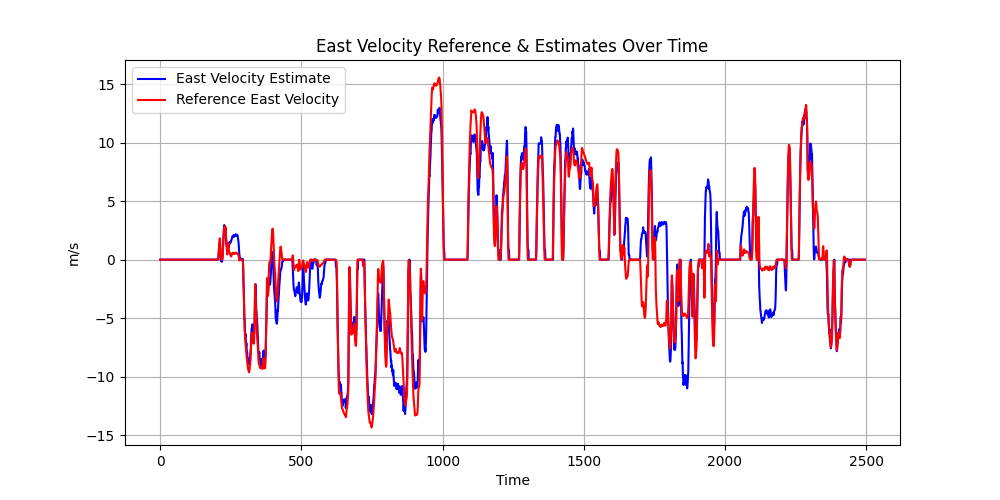

In [18]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, ve_est, label="East Velocity Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_ve, label="Reference East Velocity", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("m/s")
plt.title("East Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

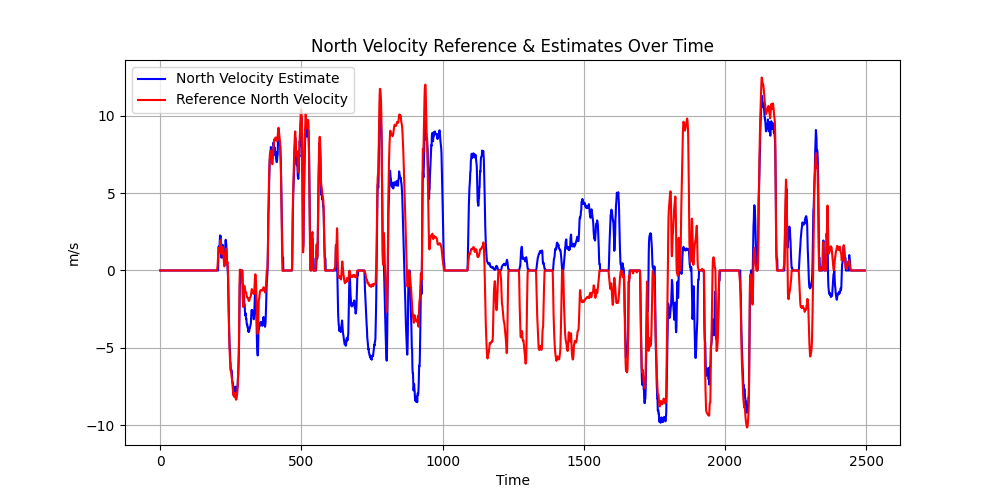

In [19]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, vn_est, label="North Velocity Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_vn, label="Reference North Velocity", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("m/s")
plt.title("North Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

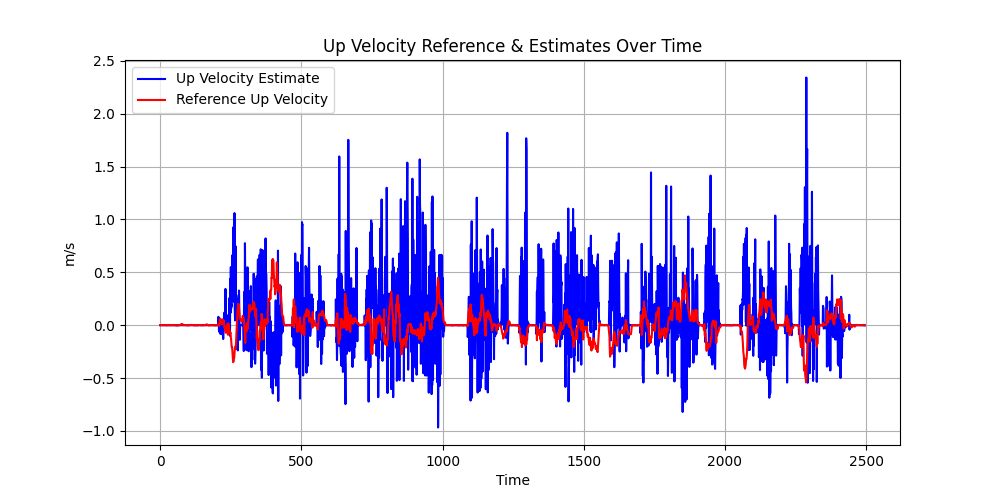

In [20]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, vu_est, label="Up Velocity Estimate", linestyle='-', color='b')
plt.plot(time_grid, ref_vu, label="Reference Up Velocity", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("m/s")
plt.title("Up Velocity Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

### Attitude

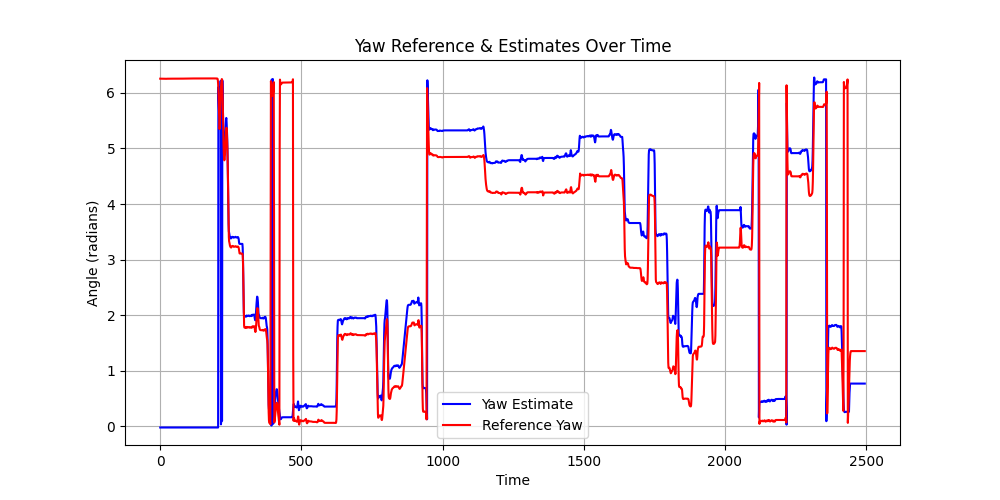

In [21]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, yaw_est, label="Yaw Estimate", linestyle='-', color='b')
plt.plot(time_grid, np.radians(-1*ref_az)%(2*np.pi), label="Reference Yaw", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (radians)")
plt.title("Yaw Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

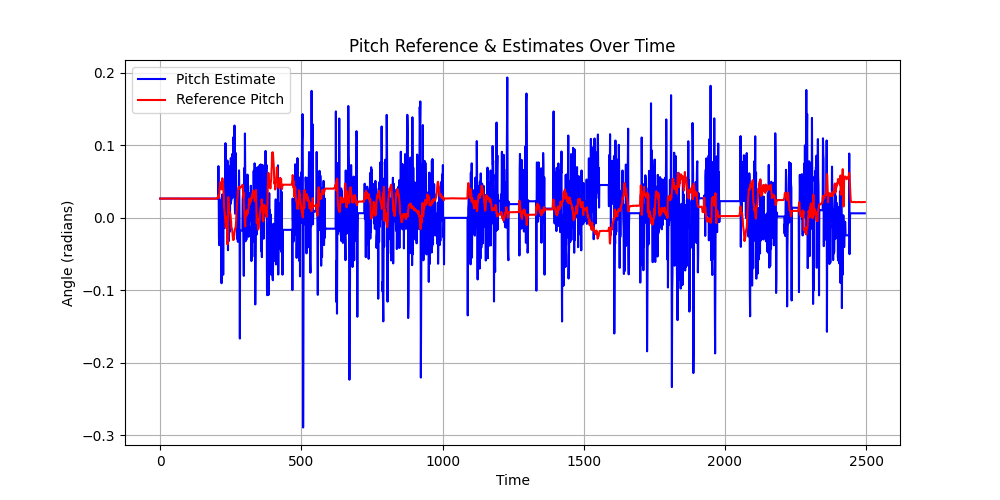

In [22]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, pitch_est, label="Pitch Estimate", linestyle='-', color='b')
plt.plot(time_grid, np.radians(ref_pitch), label="Reference Pitch", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (radians)")
plt.title("Pitch Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

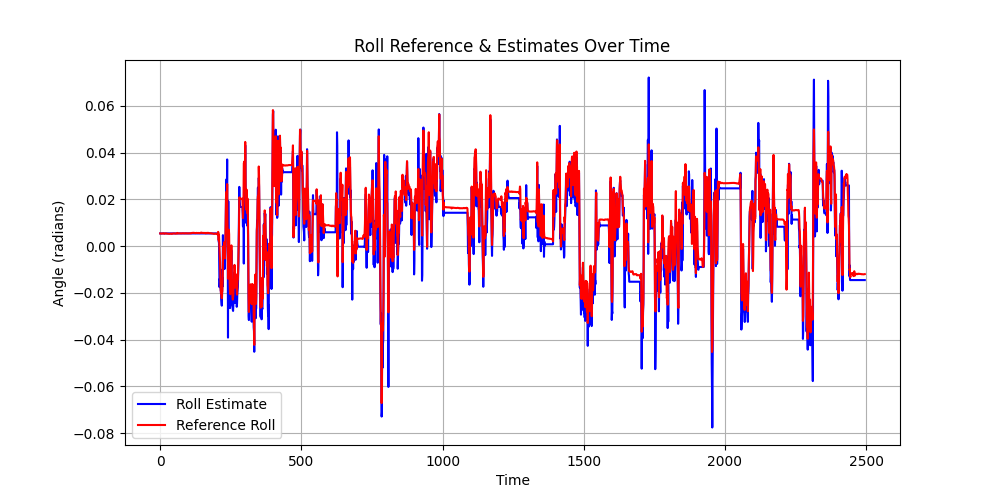

In [23]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(time_grid, roll_est, label="Roll Estimate", linestyle='-', color='b')
plt.plot(time_grid, np.radians(ref_roll), label="Reference Roll", linestyle='-', color='r')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Angle (radians)")
plt.title("Roll Reference & Estimates Over Time")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()